# Seminar. Practical aspects of diffusion models
## Part 1 — Flow matching on toy data (≈30 min)

| Notebook | What we do | Lecture slides | Time |
|---|---|---|---|
| **01_toy_flow_matching** | train a 2D flow model in 15 s; Euler vs Heun; ODE vs SDE; CFG and interval CFG; why x0-prediction | loss, solvers, guidance, pixel space | ~30 min |
| 02_tiny_dit | DiT with AdaLN from scratch on FashionMNIST; time shift; CFG vs autoguidance; FID | architectures, time distribution, evaluation, guidance | ~25 min |
| 03_big_model | Z-Image (6B MM-/single-stream DiT): own sampler, VAE, time shift, CFG sweep + CLIP score, interval CFG, negative prompt, solvers, distilled model | everything, at scale | ~35 min |

Notation follows the lecture:

$$x_t = (1-t)\,x_0 + t\,\epsilon,\qquad t\in[0,1],\qquad v = \epsilon - x_0,$$

$$\hat x_0 = x_t - t\,v,\qquad \hat\epsilon = x_t + (1-t)\,v,\qquad \nabla_{x_t}\log p_t(x_t) = -\hat\epsilon / t .$$

Sampling integrates $dx = v_\theta(x_t,t)\,dt$ from $t=1$ (noise) to $t=0$ (data).

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '2')   # pick a free GPU (check nvidia-smi)

import math, time
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(4)   # shared machine: avoid CPU oversubscription
dev = 'cuda'
torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 80, 'axes.grid': False})

## 1. Data

Two classes in 2D, built so that guidance effects are visible:
* **class 0** (green): two tight modes, **A** = (−2, 0) and **B** = (1.5, 0.6), 50/50;
* **class 1** (red): a broad blob centred at (1.5, 0) that **overlaps mode B**.

We know the true distribution, so we can measure exactly what each trick does.

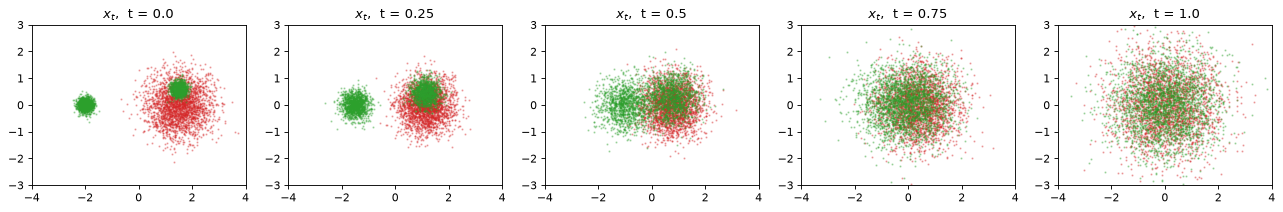

In [2]:
CENTERS = torch.tensor([[-2.0, 0.0], [1.5, 0.6]], device=dev)

def sample_data(n):
    y = torch.randint(0, 2, (n,), device=dev)
    mode = torch.randint(0, 2, (n,), device=dev)
    x_cls0 = CENTERS[mode] + 0.15 * torch.randn(n, 2, device=dev)
    x_cls1 = torch.tensor([1.5, 0.0], device=dev) + 0.6 * torch.randn(n, 2, device=dev)
    return torch.where(y[:, None] == 0, x_cls0, x_cls1), y

def scatter_data(ax, x, y, alpha=0.3):
    x, y = x.cpu(), y.cpu()
    ax.scatter(*x[y == 1].T, s=1, c='tab:red', alpha=alpha)
    ax.scatter(*x[y == 0].T, s=1, c='tab:green', alpha=alpha)
    ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal')

xd, yd = sample_data(5000)
fig, axs = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, t in zip(axs, [0.0, 0.25, 0.5, 0.75, 1.0]):
    xt = (1 - t) * xd + t * torch.randn_like(xd)
    scatter_data(ax, xt, yd); ax.set_title(f'$x_t$,  t = {t}')
plt.show()

## 2. Model and training

Velocity network $v_\theta(x_t, t, y)$: a small MLP. Class `2` is the **null class** $\varnothing$:
we drop the label with probability 0.2, so the same network learns $v(x\mid y)$ and $v(x\mid\varnothing)$ — this is all CFG needs.

Loss (flow matching / v-prediction, $w(t)=1$, $t\sim\mathcal U[0,1]$):
$$\mathcal L = \mathbb E\,\|v_\theta(x_t,t,y) - (\epsilon - x_0)\|^2 .$$

trained in 19.7s, final loss 1.158


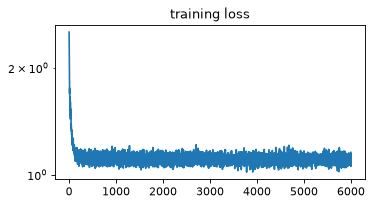

In [3]:
def time_embedding(t, dim=32):
    freqs = torch.exp(-math.log(10000) * torch.arange(dim // 2, device=t.device) / (dim // 2))
    a = 1000 * t[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], dim=-1)

class VelocityMLP(nn.Module):
    def __init__(self, d=2, h=256, n_classes=2):
        super().__init__()
        self.inp = nn.Linear(d, h)
        self.t_proj = nn.Linear(32, h)
        self.y_emb = nn.Embedding(n_classes + 1, h)      # +1 = null class
        self.net = nn.Sequential(nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h),
                                 nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, d))
    def forward(self, x, t, y):
        return self.net(self.inp(x) + self.t_proj(time_embedding(t)) + self.y_emb(y))

NULL = 2
model = VelocityMLP().to(dev)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

t0, losses = time.time(), []
for it in range(6000):
    x0, y = sample_data(4096)
    y = torch.where(torch.rand(len(y), device=dev) < 0.2, NULL, y)    # label dropout for CFG
    t = torch.rand(len(x0), device=dev)
    eps = torch.randn_like(x0)
    xt = (1 - t[:, None]) * x0 + t[:, None] * eps
    loss = F.mse_loss(model(xt, t, y), eps - x0)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
print(f'trained in {time.time() - t0:.1f}s, final loss {loss.item():.3f}')
plt.figure(figsize=(5, 2.5)); plt.plot(losses); plt.yscale('log'); plt.title('training loss'); plt.show()

## 3. Solvers

Time grid $1=t_0>t_1>\dots>t_N=0$, optionally shifted with the lecture's $s(\alpha,t)=\frac{\alpha t}{1+(\alpha-1)t}$.

* **Euler**: $x_{t_{i+1}} = x_{t_i} + (t_{i+1}-t_i)\,v_\theta(x_{t_i}, t_i)$ — 1 NFE per step.
* **Heun**: Euler predictor + trapezoidal corrector — 2 NFE per step (last step is plain Euler).

In [4]:
def time_grid(steps, shift=1.0):
    t = torch.linspace(1, 0, steps + 1, device=dev)
    return shift * t / (1 + (shift - 1) * t)

def make_velocity(y, w=1.0, interval=(0.0, 1.0)):
    """Returns v(x, t). CFG: v = v(x|∅) + w (v(x|y) - v(x|∅)), applied only for t in `interval`."""
    def v(x, t):
        tt = torch.full((len(x),), float(t), device=dev)
        v_c = model(x, tt, torch.full((len(x),), y, device=dev))
        if w == 1.0 or not (interval[0] <= t <= interval[1]):
            return v_c
        v_u = model(x, tt, torch.full((len(x),), NULL, device=dev))
        return v_u + w * (v_c - v_u)
    return v

@torch.no_grad()
def euler(x, ts, v, traj=None):
    for i in range(len(ts) - 1):
        x = x + (ts[i + 1] - ts[i]) * v(x, ts[i])
        if traj is not None: traj.append(x.cpu())
    return x

@torch.no_grad()
def heun(x, ts, v):
    for i in range(len(ts) - 1):
        h = ts[i + 1] - ts[i]
        d = v(x, ts[i])
        x_pred = x + h * d
        if ts[i + 1] > 0:                               # corrector (skip at t = 0)
            x = x + h / 2 * (d + v(x_pred, ts[i + 1]))
        else:
            x = x_pred
    return x

def swd(a, b, n_proj=256):
    """Sliced Wasserstein distance: a cheap 'FID' for 2D toy data."""
    dirs = F.normalize(torch.randn(n_proj, a.shape[1], device=dev), dim=1)
    pa, _ = torch.sort(a @ dirs.T, dim=0); pb, _ = torch.sort(b @ dirs.T, dim=0)
    return ((pa - pb) ** 2).mean().sqrt().item()

### 3.1 Trajectories and the number of steps

Unconditional sampling ($y=\varnothing$). With **one** Euler step we land on $\hat x_0 = x_1 - v_\theta(x_1, 1) = \mathbb E[x_0\mid x_1]$ — the data mean. Few steps → samples get stuck *between* the modes.

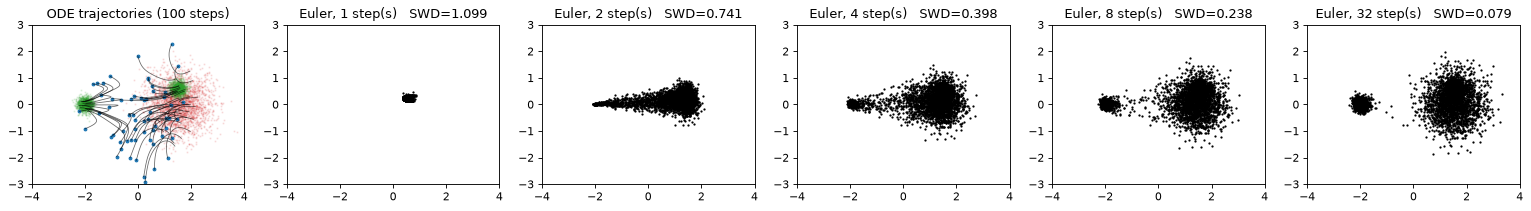

In [5]:
N = 20000                                     # many samples -> less noisy SWD
x1 = torch.randn(N, 2, device=dev)
x_ref, _ = sample_data(N)
v_uncond = make_velocity(NULL)

fig, axs = plt.subplots(1, 6, figsize=(24, 3.6))
traj = [x1[:60].cpu()]
euler(x1[:60], time_grid(100), v_uncond, traj)
traj = torch.stack(traj)                                # [T, 60, 2]
scatter_data(axs[0], xd, yd, alpha=0.1)
for k in range(60):
    axs[0].plot(traj[:, k, 0], traj[:, k, 1], lw=0.7, c='k', alpha=0.6)
axs[0].scatter(*traj[0].T, s=6, c='tab:blue'); axs[0].set_title('ODE trajectories (100 steps)')
for ax, steps in zip(axs[1:], [1, 2, 4, 8, 32]):
    s = euler(x1, time_grid(steps), v_uncond)
    ax.scatter(*s[:4000].cpu().T, s=1, c='k'); ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal')
    ax.set_title(f'Euler, {steps} step(s)   SWD={swd(s, x_ref):.3f}')
plt.show()

### 3.2 Straighter trajectories → fewer steps

Lecture: *the most effective way to get straighter trajectories — a stronger condition.*

Compare the unimodal class 1 (one Gaussian) with the bimodal class 0. Note that **one** step always returns $\mathbb E[x_0\mid y]$: at $t=1$ the noise carries no information about $x_0$.

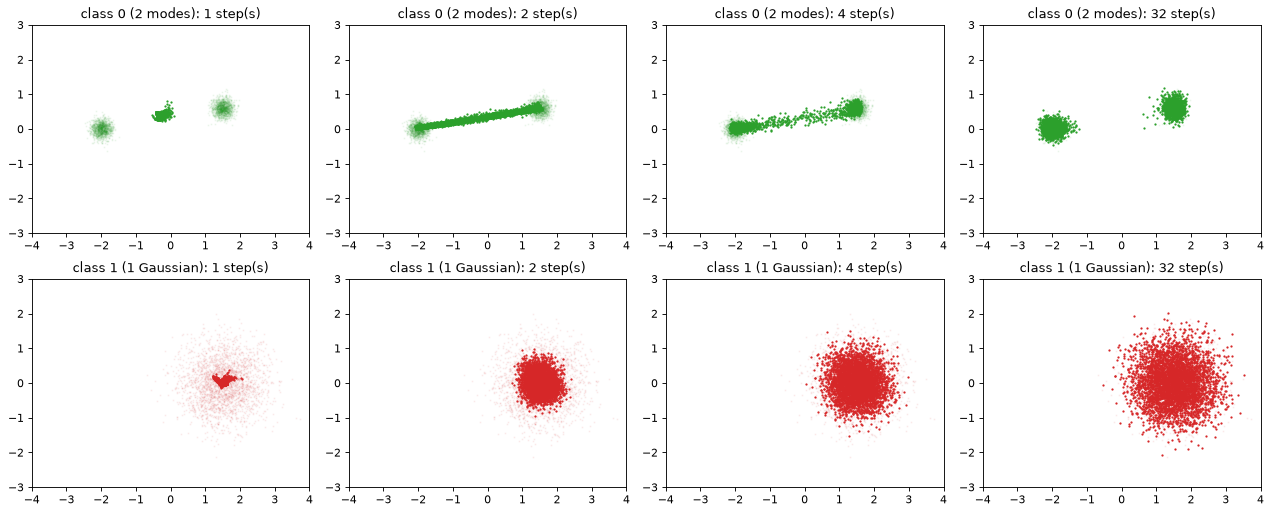

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5))
for row, (y, color, name) in enumerate([(0, 'tab:green', 'class 0 (2 modes)'), (1, 'tab:red', 'class 1 (1 Gaussian)')]):
    for col, steps in enumerate([1, 2, 4, 32]):
        s = euler(x1[:4000], time_grid(steps), make_velocity(y))
        ax = axs[row, col]
        scatter_data(ax, xd[yd == y], yd[yd == y], alpha=0.05)
        ax.scatter(*s.cpu().T, s=1, c=color)
        ax.set_title(f'{name}: {steps} step(s)')
plt.tight_layout(); plt.show()

### 3.3 Euler vs Heun at equal compute

Compare at the same number of function evaluations (NFE): Heun with $n$ steps costs $2n-1$ NFE.

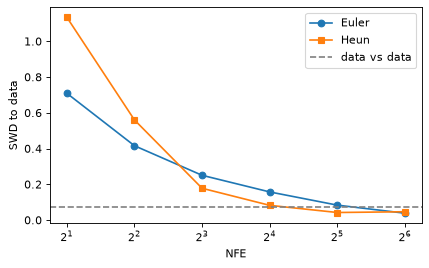

In [7]:
nfes = [2, 4, 8, 16, 32, 64]
res = {'euler': [], 'heun': []}
for nfe in nfes:
    res['euler'].append(swd(euler(x1, time_grid(nfe), v_uncond), x_ref))
    steps = (nfe + 1) // 2
    res['heun'].append(swd(heun(x1, time_grid(steps), v_uncond), x_ref))
floor = swd(sample_data(N)[0], x_ref)      # SWD between two independent data samples
plt.figure(figsize=(6, 3.5))
plt.plot(nfes, res['euler'], 'o-', label='Euler'); plt.plot(nfes, res['heun'], 's-', label='Heun')
plt.axhline(floor, ls='--', c='gray', label='data vs data')
plt.xscale('log', base=2); plt.xlabel('NFE'); plt.ylabel('SWD to data'); plt.legend(); plt.show()

### 3.4 Time grids

Same number of steps, different allocation. $\alpha>1$ puts more steps near noise, $\alpha<1$ near data.

**Question:** the modes are tight (σ = 0.15). Should we spend the steps near the data?

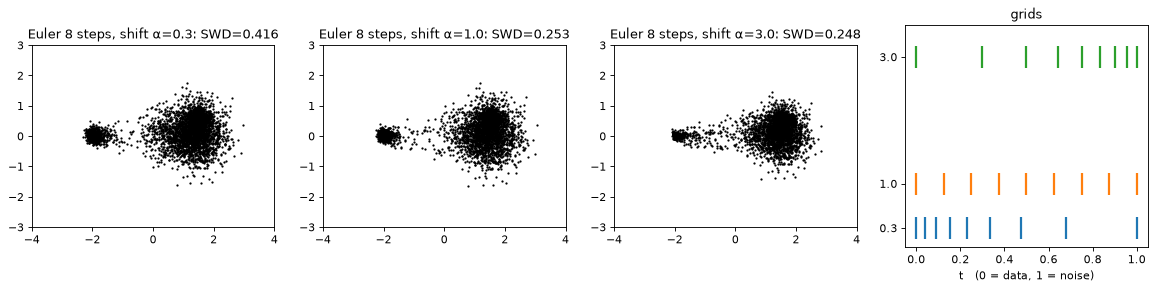

SWD, Euler:      4 steps  8 steps  16 steps
shift α=0.3    0.702    0.410    0.225
shift α=0.5    0.545    0.305    0.176
shift α=1      0.395    0.240    0.156
shift α=2      0.401    0.242    0.113
shift α=3      0.384    0.258    0.148
shift α=5      0.528    0.321    0.213


In [8]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, a in zip(axs[:3], [0.3, 1.0, 3.0]):
    g = time_grid(8, a).cpu()
    axs[3].plot(g, [a] * len(g), '|', ms=20, mew=2)
    s = euler(x1, time_grid(8, a), v_uncond)
    ax.scatter(*s[:4000].cpu().T, s=1, c='k'); ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal')
    ax.set_title(f'Euler 8 steps, shift α={a}: SWD={swd(s, x_ref):.3f}')
axs[3].set_yticks([0.3, 1, 3]); axs[3].set_ylim(0, 3.5); axs[3].set_xlabel('t   (0 = data, 1 = noise)'); axs[3].set_title('grids')
plt.show()

print('SWD, Euler:      4 steps  8 steps  16 steps')
for a in [0.3, 0.5, 1, 2, 3, 5]:
    print(f'shift α={a:<4}', '  '.join(f'{swd(euler(x1, time_grid(st, a), v_uncond), x_ref):7.3f}' for st in [4, 8, 16]))

No: spending the steps near the data ($\alpha=0.3$) is the worst choice. Samples must first decide *which mode* to go to, and that happens at intermediate/high $t$; too few steps there leave mass between the modes.
Too much shift ($\alpha=5$) is bad too. Same message as the lecture's slide: intermediate timesteps are the *difficult and important* ones.

### 3.5 ODE vs SDE

The reverse SDE with the same marginals as the ODE (for any $g(t)$):
$$dx = \big[v - \tfrac{g^2}{2}\nabla\log p_t\big]dt + g\,d\bar W .$$
With $\nabla\log p_t = -\hat\epsilon/t$ and $g^2 = 2\eta t$ the update is simply
$$x_{t+\Delta t} = x_t + (v + \eta\,\hat\epsilon)\,\Delta t + \sqrt{2\eta t\,|\Delta t|}\;z .$$
$\eta=0$ is the ODE. Same initial noise → ODE gives **one** point, SDE gives a **cloud**.

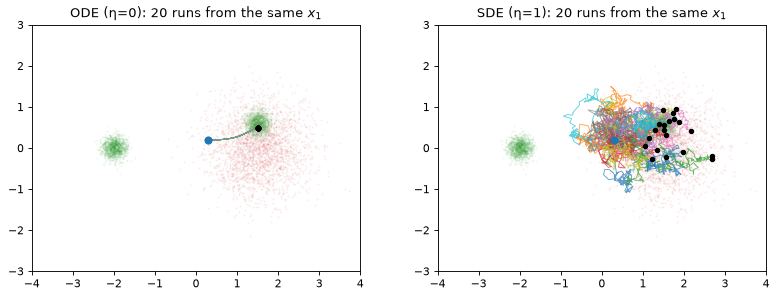

SWD to data       10 st   25 st   50 st
η=0.0:           0.177  0.086  0.042
η=1.0:           0.155  0.034  0.028


In [9]:
@torch.no_grad()
def sde(x, ts, v, eta=1.0, traj=None):
    for i in range(len(ts) - 1):
        t, dt = ts[i], ts[i + 1] - ts[i]
        vt = v(x, t)
        eps_hat = x + (1 - t) * vt
        x = x + (vt + eta * eps_hat) * dt + (2 * eta * t * dt.abs()).sqrt() * torch.randn_like(x)
        if traj is not None: traj.append(x.cpu())
    return x

x_start = torch.tensor([[0.3, 0.2]], device=dev).repeat(20, 1)       # one noise, 20 copies
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, eta, name in [(axs[0], 0.0, 'ODE (η=0)'), (axs[1], 1.0, 'SDE (η=1)')]:
    tr = [x_start.cpu()]
    sde(x_start, time_grid(200), v_uncond, eta, tr)
    tr = torch.stack(tr)
    scatter_data(ax, xd, yd, alpha=0.05)
    for k in range(20):
        ax.plot(tr[:, k, 0], tr[:, k, 1], lw=0.8, alpha=0.7)
    ax.scatter(*tr[-1].T, c='k', s=15, zorder=3); ax.scatter(*x_start[:1].cpu().T, c='tab:blue', s=40, zorder=3)
    ax.set_title(f'{name}: 20 runs from the same $x_1$')
plt.show()

print('SWD to data       10 st   25 st   50 st')
for eta in [0.0, 1.0]:
    print(f'η={eta}:          ', '  '.join(f'{swd(sde(x1, time_grid(st), v_uncond, eta), x_ref):.3f}' for st in [10, 25, 50]))

Both samplers target the same marginals. The SDE re-injects noise, which also corrects accumulated errors; the ODE is deterministic, which is what you need for inversion, editing and distillation.

## 4. Classifier-free guidance

$$v_{CFG} = v(x\mid\varnothing) + w\,\big(v(x\mid y) - v(x\mid\varnothing)\big)$$

Sample **class 0**. The correct answer is 50% in mode A and 50% in mode B. Mode B sits inside class 1, so $p(y=0\mid x)$ is small there and the implicit classifier gradient pushes samples away from it.

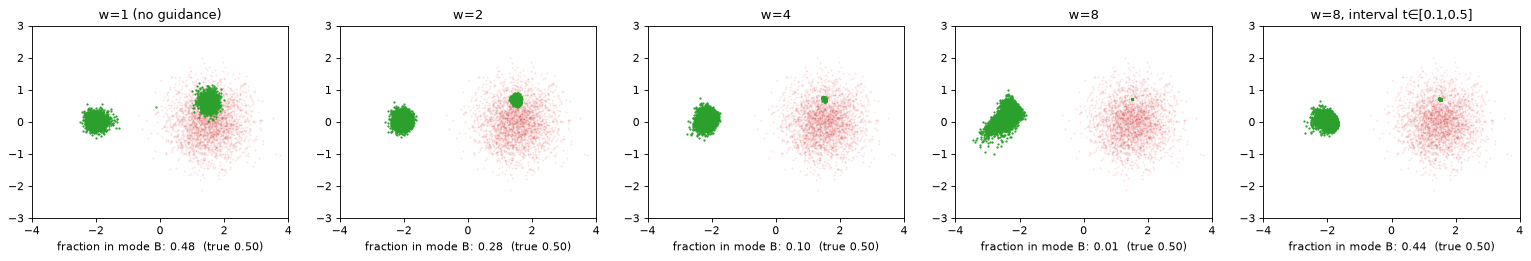

In [10]:
def frac_B(s):
    return (s[:, 0] > 0).float().mean().item()

configs = [(1.0, (0, 1), 'w=1 (no guidance)'), (2.0, (0, 1), 'w=2'), (4.0, (0, 1), 'w=4'),
           (8.0, (0, 1), 'w=8'), (8.0, (0.1, 0.5), 'w=8, interval t∈[0.1,0.5]')]
fig, axs = plt.subplots(1, 5, figsize=(24, 4))
x_cls1 = xd[yd == 1]
for ax, (w, iv, name) in zip(axs, configs):
    s = euler(x1, time_grid(100), make_velocity(0, w, iv)).cpu()
    ax.scatter(*x_cls1.cpu().T, s=1, c='tab:red', alpha=0.08)
    ax.scatter(*s[:4000].T, s=1, c='tab:green')
    ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal')
    ax.set_title(name); ax.set_xlabel(f'fraction in mode B: {frac_B(s):.2f}  (true 0.50)')
plt.show()

What we see — exactly the lecture's slides:
* **w > 1** sharpens the modes (higher "quality") and pushes samples away from class 1 — even *outside* the data support (the 2D analogue of oversaturation);
* **large w drops mode B** — reduced diversity;
* **interval guidance** (no guidance at high noise, where the modes are not separated yet, and none at the very end) keeps both modes and still sharpens them.

Where should the interval be? Try it yourself:

In [11]:
for iv in [(0.0, 1.0), (0.5, 1.0), (0.0, 0.5), (0.1, 0.5), (0.1, 0.3)]:
    s = euler(x1, time_grid(100), make_velocity(0, 8.0, iv))
    print(f'interval {iv}:  fraction in B = {frac_B(s):.2f}')

interval (0.0, 1.0):  fraction in B = 0.01
interval (0.5, 1.0):  fraction in B = 0.01
interval (0.0, 0.5):  fraction in B = 0.44


interval (0.1, 0.5):  fraction in B = 0.44
interval (0.1, 0.3):  fraction in B = 0.48


## 5. Why x0-prediction matters in pixel space

Lecture table: at 256×256, $x_0$-pred FID 8.6 vs $\epsilon$-pred 372 and $v$-pred 97.

Toy version (from the JiT paper): the data is a 2D spiral, embedded into $D$ dimensions by a random orthonormal $P\in\mathbb R^{D\times 2}$.
Images are like this: high-dimensional, but living near a low-dimensional manifold.
The **same** MLP (width 256) predicts $x_0$, $\epsilon$ or $v$; the loss is always the $v$-loss, only the parametrisation changes:
$$v = \frac{x_t - \hat x_0}{t} = \frac{\hat\epsilon - x_t}{1-t}.$$
$x_0$ is low-dimensional, $\epsilon$ and $v$ are full-dimensional noise — a narrow network cannot represent them.

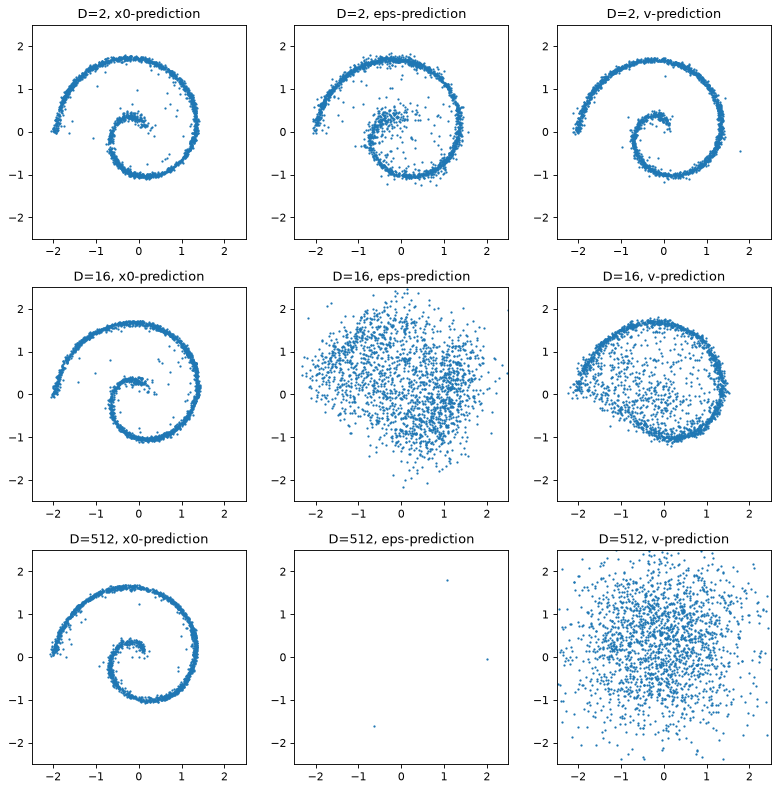

51s


In [12]:
def spiral(n):
    th = torch.sqrt(torch.rand(n, device=dev)) * 3 * math.pi
    r = th / (3 * math.pi) * 2
    x = torch.stack([r * torch.cos(th), r * torch.sin(th)], 1)
    return x + 0.03 * torch.randn_like(x)

class MLP(nn.Module):
    def __init__(self, D, h=256):
        super().__init__()
        self.inp, self.t_proj = nn.Linear(D, h), nn.Linear(32, h)
        self.net = nn.Sequential(nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, h),
                                 nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, D))
    def forward(self, x, t):
        return self.net(self.inp(x) + self.t_proj(time_embedding(t)))

def out_to_v(out, xt, t, pred):
    t = t[:, None]
    if pred == 'x0':  return (xt - out) / t.clamp(min=0.05)
    if pred == 'eps': return (out - xt) / (1 - t).clamp(min=0.05)
    return out                                                     # 'v'

def train_and_sample(D, pred, iters=3000):
    P, _ = torch.linalg.qr(torch.randn(D, D, device=dev)); P = P[:, :2]
    net = MLP(D).to(dev); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(iters):
        x0 = spiral(1024) @ P.T
        t = torch.rand(1024, device=dev); eps = torch.randn_like(x0)
        xt = (1 - t[:, None]) * x0 + t[:, None] * eps
        loss = F.mse_loss(out_to_v(net(xt, t), xt, t, pred), eps - x0)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        x, ts = torch.randn(2000, D, device=dev), time_grid(100)
        for i in range(100):
            tt = ts[i].expand(2000)
            x = x + (ts[i + 1] - ts[i]) * out_to_v(net(x, tt), x, tt, pred)
    return (x @ P).cpu()                                           # project back to 2D

t0 = time.time()
Ds, preds = [2, 16, 512], ['x0', 'eps', 'v']
fig, axs = plt.subplots(3, 3, figsize=(10, 10))
for i, D in enumerate(Ds):
    for j, pred in enumerate(preds):
        s = train_and_sample(D, pred)
        axs[i, j].scatter(*s.T, s=1); axs[i, j].set_xlim(-2.5, 2.5); axs[i, j].set_ylim(-2.5, 2.5)
        axs[i, j].set_title(f'D={D}, {pred}-prediction'); axs[i, j].set_aspect('equal')
plt.tight_layout(); plt.show()
print(f'{time.time() - t0:.0f}s')

* $D=2$: all three work.
* $D=512$: only $x_0$-prediction survives ($\epsilon$-prediction diverges, most points are off the plot). Same story as the lecture's ImageNet 256 table.
* In latent space (VAE, low-dimensional, noise-like latents) the prediction type matters much less — that is why FLUX / SD3 / Z-Image use $v$-prediction.

**Exercise:** make the MLP wider (h = 1024). Does $v$-prediction recover at $D=512$?